# B2B Score — Monitoring Notebook  (Pillars 1, 2 & 3)

Monitors the **effectiveness, stability, and business use** of the new
peer-cohort B2B Score produced by `B2B_functions_cohort_score.py`.

**How it works.** The production scorer already supports *historical* runs
(`report_as_of_dt=...`). This notebook re-runs it "as of" a series of past
month-ends, collects each client's **B2B Score** (`TotalScore = RecapScore ÷ CPRScore`)
for every month, and stacks the results into one **client × month score panel**.
Every pillar is then just an analysis of that panel — which means the *same*
notebook does the historical backtest **and** the going-forward monthly monitoring
(just extend the date window and re-run).

| Pillar | Question it answers | Backtestable today? |
|---|---|---|
| **1 — Effectiveness** | Do low-scored clients actually prepay faster later? | ✅ Yes |
| **2 — Stability** | Does a client's segment whipsaw month to month? | ✅ Yes |
| **3 — Adoption & book** | What is the business doing with the score? | ⚠️ Partly — segment mix / exposure yes; live purchase-cap compliance only after go-live |

**This is a peer score.** The CPR half of the B2B Score is `CPRScore = a client's actual
prepay ÷ the average of its peer cohorts` (clients who sent us the same kind of loans).
So **CPRScore > 1 = faster than peers**, **< 1 = slower than peers** — Pillar 1 checks the
score in these *peer* terms, exactly as production computes it, not raw prepay speed.

**Segments (CRT policy).** B2B Score **> 1.2 = Favourable**, **< 0.8 = Unfavourable**,
in-between = Neutral. CRT caps buying from Unfavourable clients at **≤ 20%**.

Run top-to-bottom. All decisions you might change live in the **USER INPUTS** cell.
Use the **`Python (B2B)`** kernel (env `B2B`) — same as the reporting notebook — and
place this file next to `B2B_Reporting_cohort_score.ipynb` (so the `functions/` folder
is importable).

## 0. USER INPUTS  —  the only cell you normally edit

In [1]:
from datetime import date
import os

# ── SCORING WINDOW ────────────────────────────────────────────────────────────
# Month-end dates to score. The backtest re-runs the scorer "as of" each of these,
# exactly as production would have on that day.
BACKTEST_START = date(2025, 7, 31)   # first month-end to score  (use real month-ends)
BACKTEST_END   = date(2025, 12, 31)   # last  month-end to score
# GOING FORWARD each month: bump BACKTEST_END to the new month-end and keep
# APPEND_TO_CACHE = True — only the new month is scored, then appended to the panel.

# ── DECISION GRAIN ────────────────────────────────────────────────────────────
# The unit CRT acts on. Client-level is the default (the 20% cap is per client).
# Use ['Client', 'PropState'] to monitor client × geography instead.
GRAIN = ['Client']

# ── FAVOURABILITY THRESHOLDS (CRT policy) ─────────────────────────────────────
FAV_THRESHOLD   = 1.2      # B2B Score >  1.2  → Favourable
UNFAV_THRESHOLD = 0.8      # B2B Score <  0.8  → Unfavourable   (between = Neutral)
CAP_UNFAV       = 0.20     # buy no more than 20% from Unfavourable clients

# ── PILLAR 1 — how far ahead to check the outcome (months) ────────────────────
FORWARD_HORIZONS = [1, 3, 6]

# ── PILLAR 2 — stability controls ─────────────────────────────────────────────
SMOOTHING_WINDOW          = 3      # months in the rolling-average score
HYSTERESIS_CONFIRM_MONTHS = 2      # a segment change must persist this many months
BOUNDARY_BUFFER           = 0.05   # "sitting on a threshold" = within this of 0.8 / 1.2

# ── general ───────────────────────────────────────────────────────────────────
MIN_CLIENTS_PER_MONTH = 30         # drop sparse early months from trend charts

# ── SQL CONNECTION  (same as the reporting notebook) ──────────────────────────
SQL_SERVER   = 'VMC2VMDBRADC01P'
SQL_DATABASE = 'Analytics_Rpt'
SQL_DRIVER   = 'ODBC Driver 17 for SQL Server'

# ── FILE PATHS  (company laptop, Windows) ─────────────────────────────────────
MONITOR_DIR = r"E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_monitoring"
PANEL_CACHE = os.path.join(MONITOR_DIR, "b2b_scored_panel.pkl")   # cached score panel

# ── RUN CONTROL ───────────────────────────────────────────────────────────────
RUN_SCORING     = False    # True  = (re)run the SQL scoring loop
                          # False = skip SQL, load the cached panel (fast re-runs)
APPEND_TO_CACHE = True    # True  = only score months missing from the cache, then append

os.makedirs(MONITOR_DIR, exist_ok=True)
REPORT_TAG = f"{BACKTEST_START:%Y%m}_{BACKTEST_END:%Y%m}"
print("Monitoring window :", BACKTEST_START, "->", BACKTEST_END)
print("Decision grain    :", GRAIN)
print("Panel cache       :", PANEL_CACHE)
print("Run scoring loop  :", RUN_SCORING, "| append to cache:", APPEND_TO_CACHE)

Monitoring window : 2025-07-31 -> 2025-12-31
Decision grain    : ['Client']
Panel cache       : E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_monitoring\b2b_scored_panel.pkl
Run scoring loop  : False | append to cache: True


## 1. Imports, connection & the production scorer

In [2]:
import sys
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

# Make the local 'functions' folder importable (identical to the reporting notebook)
FUNCTIONS_DIR = os.path.join(os.getcwd(), 'functions')
if FUNCTIONS_DIR not in sys.path:
    sys.path.insert(0, FUNCTIONS_DIR)

import B2B_functions_cohort_score as bf
from B2B_functions_cohort_score import sql_connection, B2BPricingReporter

# Spearman rank correlation if available; safe fallback otherwise
try:
    from scipy.stats import spearmanr
    _HAVE_SCIPY = True
except Exception:
    _HAVE_SCIPY = False

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
plt.rcParams['figure.figsize'] = (9, 4.2)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print('functions loaded from:', bf.__file__)
engine = sql_connection(server=SQL_SERVER, database=SQL_DATABASE, driver=SQL_DRIVER)
engine

functions loaded from: e:\Development\Shashi\B2B-Pricing-Model\repo\python\functions\B2B_functions_cohort_score.py


Engine(mssql+pyodbc:///?odbc_connect=DRIVER%3D%7BODBC+Driver+17+for+SQL+Server%7D%3BSERVER%3DVMC2VMDBRADC01P%3BDATABASE%3DAnalytics_Rpt%3BTrusted_Connection%3Dyes)

## 2. Build the monthly score panel

For each month-end in the window we call the **exact production scorer**
(`B2BPricingReporter(engine).load(report_as_of_dt=m)` → `build_groupby_summary(GRAIN)`)
and keep the per-client scores. The result is one tidy table:
one row per **client × month**, with that month's `B2B` score and its ingredients.

This is the slow step (each month runs the same SQL the monthly report runs), so the
panel is **cached to disk**. Re-runs with `RUN_SCORING = False` load the cache instantly;
going forward, `APPEND_TO_CACHE = True` scores only the new month.

In [3]:
def month_ends(start: date, end: date):
    # Every month-end date from start..end inclusive
    outs, y, m = [], start.year, start.month
    while True:
        d = date(y, m, calendar.monthrange(y, m)[1])
        if d > end:
            break
        outs.append(d)
        y, m = (y + 1, 1) if m == 12 else (y, m + 1)
    return outs

# Columns we carry forward from the production output (kept if present)
KEEP_COLS = ['LoanCt', 'FundedLoanAmt', 'ModelCPR', 'ActualCPR', 'CPRScore',
             'RecapLoanct', 'CohortRecap', 'ActualRecap', 'RecapScore', 'TotalScore']

def score_one_month(as_of: date, grain=GRAIN) -> pd.DataFrame:
    # Re-run the production scorer "as of" one past month-end; return a tidy per-client frame
    rep = B2BPricingReporter(engine).load(report_as_of_dt=as_of)
    df  = rep.build_groupby_summary(list(grain))
    cols = list(grain) + [c for c in KEEP_COLS if c in df.columns]
    out  = df[cols].copy()
    out.insert(0, 'AsOf', pd.Timestamp(as_of))
    return out

all_months = month_ends(BACKTEST_START, BACKTEST_END)

# Load existing cache (if any)
cached = None
if os.path.exists(PANEL_CACHE):
    try:
        cached = pd.read_pickle(PANEL_CACHE)
        cached['AsOf'] = pd.to_datetime(cached['AsOf'])
        print(f"Cache found: {cached.shape[0]:,} rows, "
              f"{cached['AsOf'].dt.date.nunique()} months.")
    except Exception as e:
        print("Could not read cache:", e)
        cached = None

if not RUN_SCORING:
    assert cached is not None, "RUN_SCORING=False but no cached panel exists yet."
    panel = cached.copy()
    print("Loaded cached panel (no scoring run):", panel.shape)
else:
    have = set(cached['AsOf'].dt.date.unique()) if (cached is not None and APPEND_TO_CACHE) else set()
    todo = [m for m in all_months if m not in have]
    print(f"Scoring {len(todo)} month(s): " + (", ".join(str(m) for m in todo) or "none (all cached)"))
    frames = []
    for i, m in enumerate(todo, 1):
        print(f"  [{i}/{len(todo)}] scoring as of {m} ...", flush=True)
        try:
            frames.append(score_one_month(m))
        except Exception as e:
            print(f"    !! failed for {m}: {e}")
    new_part = pd.concat(frames, ignore_index=True) if frames else None
    parts = [x for x in ((cached if APPEND_TO_CACHE else None), new_part) if x is not None]
    panel = pd.concat(parts, ignore_index=True) if parts else new_part
    panel = (panel.drop_duplicates(subset=['AsOf'] + list(GRAIN), keep='last')
                  .reset_index(drop=True))
    panel.to_pickle(PANEL_CACHE)
    print("Panel saved to cache:", PANEL_CACHE, "|", panel.shape)

# Restrict to the requested window and add convenience keys
panel = panel[panel['AsOf'].between(pd.Timestamp(BACKTEST_START),
                                    pd.Timestamp(BACKTEST_END))].copy()
panel['Month']    = panel['AsOf'].dt.to_period('M').dt.to_timestamp('M')
panel['MonthIdx'] = (panel['AsOf'].dt.year * 12 + panel['AsOf'].dt.month).astype(int)
print("\nMonths in panel :", panel['AsOf'].dt.date.nunique(),
      "| avg clients/month:", round(panel.groupby('AsOf').size().mean(), 0))
panel.head()

Cache found: 4,744 rows, 6 months.
Loaded cached panel (no scoring run): (4744, 12)

Months in panel : 6 | avg clients/month: 791.0


,AsOf,Client,LoanCt,FundedLoanAmt,ModelCPR,ActualCPR,CPRScore,RecapLoanct,CohortRecap,ActualRecap,RecapScore,TotalScore,Month,MonthIdx
0,2025-07-31,1ST 2ND MORTGAGE COMPANY OF NJ INC,10,4677858.96,0.048942,0.031246,0.638425,5,0.053033,0.000000,0.000000,0.783177,2025-07-31,24307
1,2025-07-31,1ST FINANCIAL INC,12,5197716.00,0.051585,0.036673,0.710918,3,0.201445,0.000000,1.000000,1.406633,2025-07-31,24307
2,2025-07-31,1ST NATIONAL BANK,16,6410881.90,0.064314,0.038837,0.603860,0,NaN,NaN,1.000000,1.656014,2025-07-31,24307
3,2025-07-31,1ST PRIORITY MORTGAGE INC,18,7080354.30,0.177704,0.074325,0.418252,7,0.178834,0.526889,2.946245,7.044194,2025-07-31,24307
4,2025-07-31,1ST RATE HOME MORTGAGE INC,53,15770565.91,0.062100,0.017736,0.285611,5,0.232527,0.000000,0.000000,1.750631,2025-07-31,24307


## 3. Turn scores into segments — raw, smoothed, and buffered

Each month every client is labelled **Favourable / Neutral / Unfavourable** from its
B2B score. We build three versions so Pillar 2 can *show* how to tame the whipsaw:

- **`Segment`** — the raw monthly label (what a naive rule would give).
- **`Segment_smooth`** — from a **3-month rolling-average** score (one noisy month can't reclassify).
- **`Segment_hyst`** — a **confirmation rule**: a client only changes segment after the new
  label persists for `HYSTERESIS_CONFIRM_MONTHS` months (how credit ratings avoid flip-flopping).

In [4]:
KEY = list(GRAIN)
SEG_ORDER = ['Favourable', 'Neutral', 'Unfavourable']

def to_segment(score, fav=FAV_THRESHOLD, unfav=UNFAV_THRESHOLD):
    if pd.isna(score):   return 'Neutral'
    if score > fav:      return 'Favourable'
    if score < unfav:    return 'Unfavourable'
    return 'Neutral'

panel = panel.sort_values(KEY + ['MonthIdx']).reset_index(drop=True)
panel['B2B']     = panel['TotalScore']
panel['Segment'] = panel['B2B'].apply(to_segment)

# smoothed score + its segment
panel['B2B_smooth'] = (panel.groupby(KEY)['B2B']
                       .transform(lambda s: s.rolling(SMOOTHING_WINDOW, min_periods=1).mean()))
panel['Segment_smooth'] = panel['B2B_smooth'].apply(to_segment)

# hysteresis (confirm a change over N consecutive months)
def apply_hysteresis(seg_list, confirm=HYSTERESIS_CONFIRM_MONTHS):
    eff, cur, pend, cnt = [], seg_list[0], None, 0
    for s in seg_list:
        if s == cur:
            pend, cnt = None, 0
        else:
            cnt = cnt + 1 if s == pend else 1
            pend = s
            if cnt >= confirm:
                cur, pend, cnt = s, None, 0
        eff.append(cur)
    return eff

panel['Segment_hyst'] = (panel.groupby(KEY)['Segment']
                         .transform(lambda s: pd.Series(apply_hysteresis(list(s)), index=s.index)))

display(panel[['AsOf'] + KEY + ['B2B', 'Segment', 'B2B_smooth',
                                'Segment_smooth', 'Segment_hyst']].head(12))
print("\nSegment mix (raw, all months):")
print(panel['Segment'].value_counts(normalize=True).reindex(SEG_ORDER).round(3).to_string())

,AsOf,Client,B2B,Segment,B2B_smooth,Segment_smooth,Segment_hyst
0,2025-07-31,1ST 2ND MORTGAGE COMPANY OF NJ INC,0.783177,Unfavourable,0.783177,Unfavourable,Unfavourable
1,2025-08-31,1ST 2ND MORTGAGE COMPANY OF NJ INC,0.633366,Unfavourable,0.708271,Unfavourable,Unfavourable
2,2025-09-30,1ST 2ND MORTGAGE COMPANY OF NJ INC,0.653492,Unfavourable,0.690012,Unfavourable,Unfavourable
3,2025-10-31,1ST 2ND MORTGAGE COMPANY OF NJ INC,0.627899,Unfavourable,0.638252,Unfavourable,Unfavourable
4,2025-11-30,1ST 2ND MORTGAGE COMPANY OF NJ INC,0.644225,Unfavourable,0.641872,Unfavourable,Unfavourable
5,2025-12-31,1ST 2ND MORTGAGE COMPANY OF NJ INC,0.669430,Unfavourable,0.647185,Unfavourable,Unfavourable
6,2025-07-31,1ST FINANCIAL INC,1.406633,Favourable,1.406633,Favourable,Favourable
7,2025-08-31,1ST FINANCIAL INC,1.362390,Favourable,1.384511,Favourable,Favourable
8,2025-09-30,1ST FINANCIAL INC,1.423824,Favourable,1.397616,Favourable,Favourable
9,2025-10-31,1ST FINANCIAL INC,0.618556,Unfavourable,1.134923,Neutral,Favourable



Segment mix (raw, all months):
Segment
Favourable      0.319
Neutral         0.281
Unfavourable    0.400


## Pillar 1 — Is the score RIGHT?  *(the peer-cohort test)*

**This is a peer score, not an absolute one.** Production compares each client's actual
prepayment to the **average of the peers who sent us the same kind of loans** (same
investor, loan age, credit, balance, and rate-vs-market). That ratio is the **CPRScore**:

> **CPRScore  =  client's actual prepay  ÷  its peer-cohort benchmark**
> &nbsp;&nbsp;→&nbsp;&nbsp; **above 1.0 = FASTER than peers** &nbsp;·&nbsp; **below 1.0 = SLOWER than peers**

So a client is flagged **not** because it prepays fast in absolute terms, but because it
prepays **faster than its peers**. We therefore monitor the CPR side in *peer* terms —
using CPRScore, exactly as production computes it — **not** raw prepay speed, which would
tell a different, loan-mix-driven story. Two simple checks:

1. **Does the score place clients correctly vs their peers?** Favourable clients should sit
   *below* their peer benchmark (CPRScore < 1); Unfavourable *above* it (CPRScore > 1).
2. **Does that peer position stick?** A client slower-than-peers this month should still be
   slower-than-peers in the months that follow — real behaviour, not a one-month blip.

Where each segment sits vs its peers  (CPRScore 1.0 = exactly in line with peers):


,CPRScore,OwnActualCPR,PeerBenchmark
Segment,,,
Favourable,0.5946,0.0594,0.1051
Neutral,1.0161,0.0732,0.0793
Unfavourable,1.0550,0.0534,0.0619


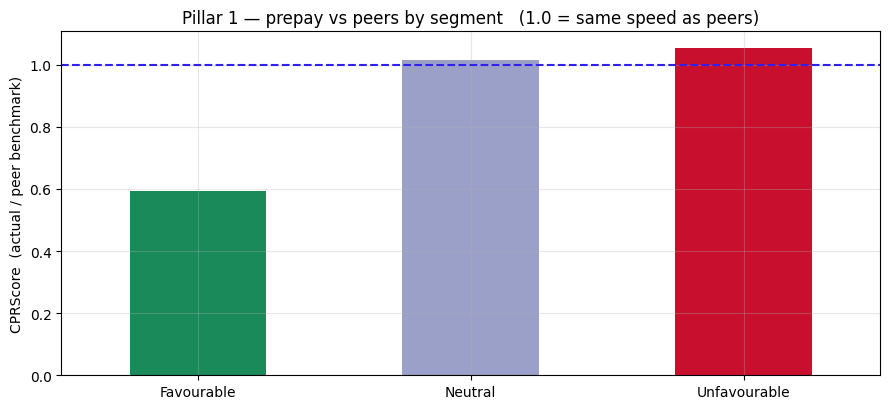

Favourable should be BELOW 1 (slower than peers); Unfavourable ABOVE 1 (faster than peers).


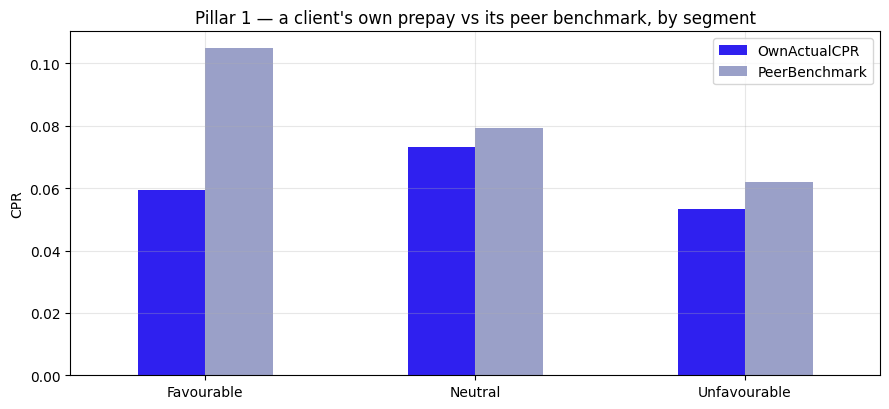


FUTURE position vs peers (CPRScore) by TODAY's segment (Unfavourable should STAY above 1, Favourable below):


,+1m,+3m,+6m
Segment,,,
Favourable,0.6121,0.6380,NaN
Neutral,1.0103,0.9701,NaN
Unfavourable,1.0450,1.0443,NaN


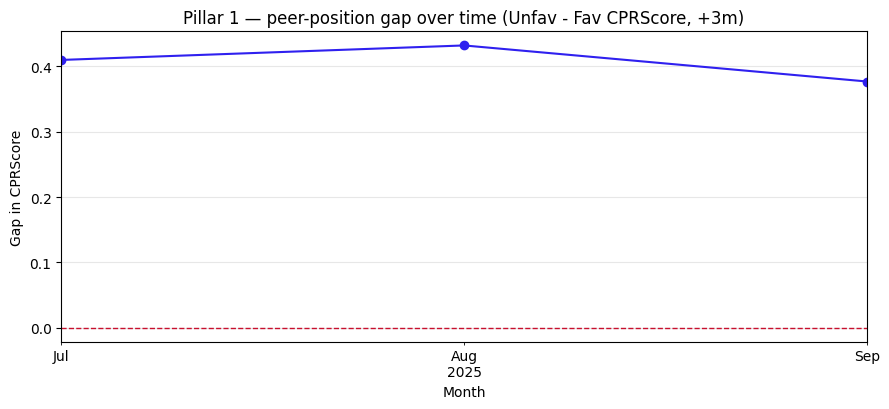

Average peer-position gap (+3m): +0.406 (positive = the peer ranking holds up over time)

Does a client's position vs peers persist?  (CPRScore now vs later, Spearman):
   over 1 month(s): +0.956   (higher = real signal, not month-to-month noise)
   over 3 month(s): +0.876   (higher = real signal, not month-to-month noise)
   over 6 month(s): +nan   (higher = real signal, not month-to-month noise)


In [5]:
# Pillar 1 works in PEER terms: CPRScore = actual prepay / peer-cohort benchmark
# (exactly the production number). ModelCPR is the peer benchmark itself.

# 1) RIGHT NOW: where does each segment sit vs its peers? ---------------------
now = (panel.groupby('Segment')
       .agg(CPRScore=('CPRScore', 'mean'),
            OwnActualCPR=('ActualCPR', 'mean'),
            PeerBenchmark=('ModelCPR', 'mean'))
       .reindex(SEG_ORDER))
print("Where each segment sits vs its peers  (CPRScore 1.0 = exactly in line with peers):")
display(now.round(4))

ax = now['CPRScore'].plot(kind='bar', color=['#1B8A5A', '#9AA0C8', '#C8102E'])
ax.axhline(1.0, color='#2F20EF', lw=1.5, ls='--')
ax.set_title("Pillar 1 — prepay vs peers by segment   (1.0 = same speed as peers)")
ax.set_ylabel("CPRScore  (actual / peer benchmark)"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Favourable should be BELOW 1 (slower than peers); Unfavourable ABOVE 1 (faster than peers).")

# Make the peer comparison explicit: a client's OWN prepay vs its PEER benchmark
ax = now[['OwnActualCPR', 'PeerBenchmark']].plot(kind='bar', color=['#2F20EF', '#9AA0C8'])
ax.set_title("Pillar 1 — a client's own prepay vs its peer benchmark, by segment")
ax.set_ylabel("CPR"); ax.set_xlabel(""); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

# 2) DOES IT STICK?  attach each client's FUTURE peer position (CPRScore) ------
def attach_forward(base, horizon):
    # bring each client's future CPRScore (peer-relative) back onto the base month
    fut = panel[KEY + ['MonthIdx', 'CPRScore']].rename(
        columns={'CPRScore': f'CPRw_f{horizon}'}).copy()
    fut['MonthIdx'] = fut['MonthIdx'] - horizon
    return base.merge(fut, on=KEY + ['MonthIdx'], how='left')

fwd = panel.copy()
for h in FORWARD_HORIZONS:
    fwd = attach_forward(fwd, h)

rows = []
for h in FORWARD_HORIZONS:
    g = fwd.dropna(subset=[f'CPRw_f{h}']).groupby('Segment')[f'CPRw_f{h}'].mean()
    for seg in SEG_ORDER:
        rows.append({'Segment': seg, f'+{h}m': g.get(seg, np.nan)})
fwd_tbl = pd.DataFrame(rows).groupby('Segment').first().reindex(SEG_ORDER)
print("\nFUTURE position vs peers (CPRScore) by TODAY's segment "
      "(Unfavourable should STAY above 1, Favourable below):")
display(fwd_tbl.round(4))

# gap over time: do Unfavourable clients STAY more-above-peers than Favourable?
H_SEP = 3 if 3 in FORWARD_HORIZONS else FORWARD_HORIZONS[0]
gap = (fwd.dropna(subset=[f'CPRw_f{H_SEP}'])
          .groupby(['Month', 'Segment'])[f'CPRw_f{H_SEP}'].mean().unstack())
if {'Favourable', 'Unfavourable'}.issubset(gap.columns):
    gap['Gap'] = gap['Unfavourable'] - gap['Favourable']
    gp = gap.dropna(subset=['Gap'])
    if len(gp):
        ax = gp['Gap'].plot(marker='o', color='#2F20EF')
        ax.axhline(0, color='#C8102E', lw=1, ls='--')
        ax.set_title(f"Pillar 1 — peer-position gap over time (Unfav - Fav CPRScore, +{H_SEP}m)")
        ax.set_ylabel("Gap in CPRScore"); plt.tight_layout(); plt.show()
        print(f"Average peer-position gap (+{H_SEP}m): {gp['Gap'].mean():+.3f} "
              "(positive = the peer ranking holds up over time)")

# 3) Does a client's position vs peers PERSIST? (CPRScore now vs later) --------
def spear(a, b):
    m = a.notna() & b.notna()
    if m.sum() < 10: return np.nan
    if _HAVE_SCIPY:  return spearmanr(a[m], b[m]).correlation
    return a[m].rank().corr(b[m].rank())

print("\nDoes a client's position vs peers persist?  (CPRScore now vs later, Spearman):")
for h in FORWARD_HORIZONS:
    print(f"   over {h} month(s): {spear(fwd['CPRScore'], fwd[f'CPRw_f{h}']):+.3f}   "
          "(higher = real signal, not month-to-month noise)")

## Pillar 2 — Is the score STABLE enough to act on?  *(the CRT's #1 concern)*

CRT can't flip buying every month, so we measure churn **and** show two simple fixes.

- **Transition matrix** — where clients in each segment last month ended up this month (diagonal = stayed).
- **Persistence rate** — % of clients that stayed in the same segment (higher = calmer).
- **Extreme-flip rate** — % that jumped Favourable ↔ Unfavourable in one step (these are the whipsaws).
- **Score volatility** — the typical month-to-month move in the raw score.
- **Boundary population** — clients sitting right on a 0.8 / 1.2 line (they flip on noise).
- **The fix, quantified** — the same flip rate under the raw label vs the **smoothed** and **confirmation** rules.

Month-over-month transition matrix (rows = last month, cols = this month), counts:


Segment,Favourable,Neutral,Unfavourable
prev_seg,,,
Favourable,1146,77,21
Neutral,75,918,108
Unfavourable,45,86,1436


Same, as row percentages:


Segment,Favourable,Neutral,Unfavourable
prev_seg,,,
Favourable,0.921,0.062,0.017
Neutral,0.068,0.834,0.098
Unfavourable,0.029,0.055,0.916



Persistence rate (stayed in same segment):  89.5%
Extreme-flip rate (Fav <-> Unfav in one step):   1.7%
Typical monthly move in B2B score (median |Δ|): 0.034
Clients sitting within ±0.05 of a threshold:   8.6% (these flip most easily on noise)


,Persistence %,Extreme-flip %
Raw monthly,89.5,1.7
3-mo smoothed,93.1,0.6
2-mo confirm,94.7,1.1


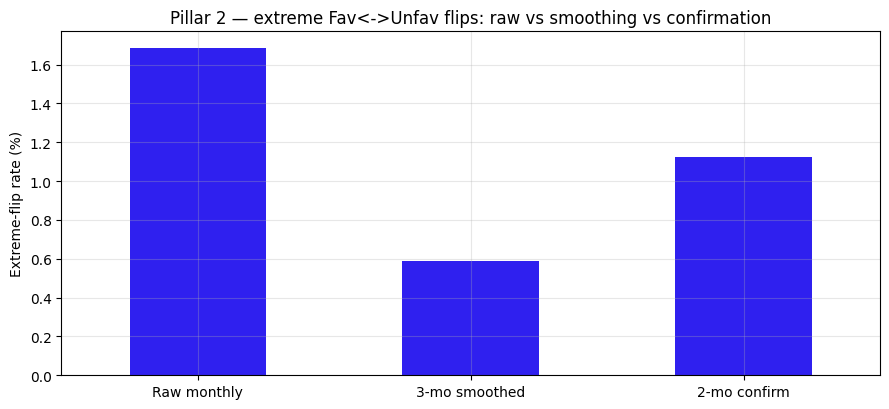

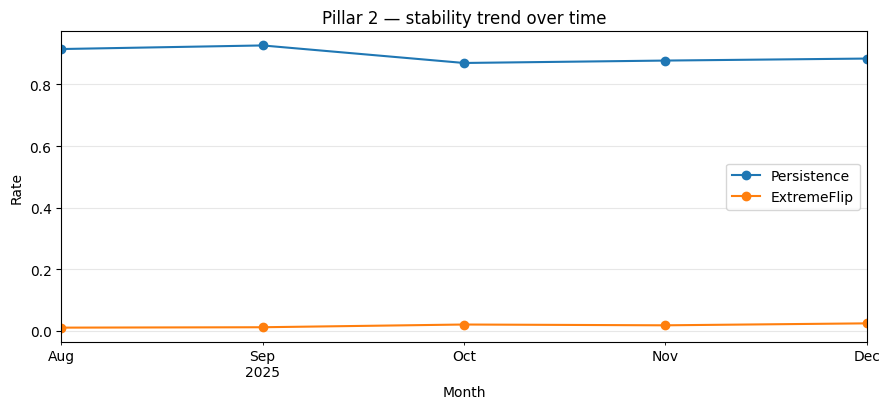

In [6]:
def consecutive_transitions(df, seg_col):
    # Rows where a client has BOTH this month and the immediately prior month
    d = df.sort_values(KEY + ['MonthIdx']).copy()
    d['prev_seg'] = d.groupby(KEY)[seg_col].shift(1)
    d['prev_idx'] = d.groupby(KEY)['MonthIdx'].shift(1)
    d['prev_b2b'] = d.groupby(KEY)['B2B'].shift(1)
    return d[(d['MonthIdx'] - d['prev_idx']) == 1].copy()

def stability_metrics(df, seg_col):
    tr = consecutive_transitions(df, seg_col)
    if tr.empty:
        return None, np.nan, np.nan, tr
    mat = (pd.crosstab(tr['prev_seg'], tr[seg_col])
           .reindex(index=SEG_ORDER, columns=SEG_ORDER).fillna(0).astype(int))
    persistence = np.diag(mat.values).sum() / mat.values.sum()
    extreme = tr[((tr['prev_seg'] == 'Favourable')   & (tr[seg_col] == 'Unfavourable')) |
                 ((tr['prev_seg'] == 'Unfavourable') & (tr[seg_col] == 'Favourable'))].shape[0] / len(tr)
    return mat, persistence, extreme, tr

mat, persistence, extreme, tr = stability_metrics(panel, 'Segment')
print("Month-over-month transition matrix (rows = last month, cols = this month), counts:")
display(mat)
print("Same, as row percentages:")
display(mat.div(mat.sum(1), axis=0).round(3))
print(f"\nPersistence rate (stayed in same segment): {persistence:6.1%}")
print(f"Extreme-flip rate (Fav <-> Unfav in one step): {extreme:6.1%}")

# score volatility
tr['dB2B'] = (tr['B2B'] - tr['prev_b2b']).abs()
print(f"Typical monthly move in B2B score (median |Δ|): {tr['dB2B'].median():.3f}")

# boundary population
near = ((panel['B2B'].sub(UNFAV_THRESHOLD).abs() <= BOUNDARY_BUFFER) |
        (panel['B2B'].sub(FAV_THRESHOLD).abs()   <= BOUNDARY_BUFFER))
print(f"Clients sitting within ±{BOUNDARY_BUFFER} of a threshold: {near.mean():6.1%} "
      "(these flip most easily on noise)")

# the fix, quantified: raw vs smoothed vs hysteresis
comp = {}
for label, col in [('Raw monthly', 'Segment'),
                   (f'{SMOOTHING_WINDOW}-mo smoothed', 'Segment_smooth'),
                   (f'{HYSTERESIS_CONFIRM_MONTHS}-mo confirm', 'Segment_hyst')]:
    _, pers, ext, _ = stability_metrics(panel, col)
    comp[label] = {'Persistence': pers, 'Extreme-flip': ext}
comp = pd.DataFrame(comp).T
display((comp * 100).round(1).rename(columns=lambda c: c + ' %'))

ax = (comp['Extreme-flip'] * 100).plot(kind='bar', color='#2F20EF')
ax.set_title("Pillar 2 — extreme Fav<->Unfav flips: raw vs smoothing vs confirmation")
ax.set_ylabel("Extreme-flip rate (%)"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# persistence / extreme-flip trend by month
trend = []
for mi, g in panel.groupby('MonthIdx'):
    sub = consecutive_transitions(panel[panel['MonthIdx'].isin([mi - 1, mi])], 'Segment')
    sub = sub[sub['MonthIdx'] == mi]
    if len(sub) >= MIN_CLIENTS_PER_MONTH:
        pers = (sub['prev_seg'] == sub['Segment']).mean()
        ext  = (((sub['prev_seg']=='Favourable')&(sub['Segment']=='Unfavourable'))|
                ((sub['prev_seg']=='Unfavourable')&(sub['Segment']=='Favourable'))).mean()
        trend.append({'Month': g['Month'].iloc[0], 'Persistence': pers, 'ExtremeFlip': ext})
trend = pd.DataFrame(trend)
if len(trend):
    ax = trend.set_index('Month')[['Persistence', 'ExtremeFlip']].plot(marker='o')
    ax.set_title("Pillar 2 — stability trend over time"); ax.set_ylabel("Rate")
    plt.tight_layout(); plt.show()

## Pillar 3 — What is the business DOING with the score?  *(adoption & book)*

This is the "what strategy is the score shaping" view. **Note on backtesting:** the buying
policy (the ≤20% cap) was not live in the past, so *cap-compliance* is only meaningful
**after go-live**. What we *can* compute today — and what becomes the live monitoring —
is the **segment mix of the book/volume**: how much of what we hold and buy is tied to
Favourable vs Unfavourable clients, and how those pools move over time. Treat the pre-go-live
numbers as a **baseline** the policy is meant to improve.

In [ ]:
# Segment population over time (client counts)
pop = (panel.groupby(['Month', 'Segment']).size().unstack()
       .reindex(columns=SEG_ORDER).fillna(0))
ax = pop.plot(kind='area', alpha=0.75, color=['#1B8A5A', '#9AA0C8', '#C8102E'])
ax.set_title("Pillar 3 — how many clients are in each segment over time")
ax.set_ylabel("Clients"); plt.tight_layout(); plt.show()

# Funded-volume share by segment (the 'mix' — baseline today, live post-go-live)
fund = (panel.groupby(['Month', 'Segment'])['FundedLoanAmt'].sum().unstack()
        .reindex(columns=SEG_ORDER).fillna(0))
fund_share = fund.div(fund.sum(1), axis=0)
ax = fund_share.plot(kind='area', alpha=0.75, color=['#1B8A5A', '#9AA0C8', '#C8102E'])
ax.set_title("Pillar 3 — share of funded volume by client segment")
ax.set_ylabel("Share of $ volume"); ax.set_ylim(0, 1); plt.tight_layout(); plt.show()

# Unfavourable share vs the 20% cap (the compliance view — real after go-live)
unfav_share = fund_share['Unfavourable'] if 'Unfavourable' in fund_share else pd.Series(dtype=float)
if len(unfav_share):
    ax = unfav_share.plot(marker='o', color='#C8102E', label='Unfavourable $ share')
    ax.axhline(CAP_UNFAV, color='#2F20EF', ls='--', label=f'{CAP_UNFAV:.0%} cap')
    ax.set_title("Pillar 3 — Unfavourable-client volume share vs the cap "
                 "(baseline pre-go-live)")
    ax.set_ylabel("Share of $ volume"); ax.legend(); plt.tight_layout(); plt.show()
    comp_tbl = pd.DataFrame({'Unfav $ share': unfav_share,
                             'Over cap?': unfav_share > CAP_UNFAV})
    display(comp_tbl.tail(12).round(3))

# Book exposure by CURRENT segment (latest month)
latest = panel['MonthIdx'].max()
lm = panel[panel['MonthIdx'] == latest]
exp = (lm.groupby('Segment')['FundedLoanAmt'].agg(['size', 'sum'])
       .reindex(SEG_ORDER).rename(columns={'size': 'Clients', 'sum': 'FundedLoanAmt'}))
exp['$ share'] = (exp['FundedLoanAmt'] / exp['FundedLoanAmt'].sum()).round(3)
print(f"Book exposure by current segment (as of {lm['AsOf'].iloc[0].date()}):")
display(exp.assign(FundedLoanAmt=exp['FundedLoanAmt'].map('${:,.0f}'.format)))

# "Bought-while-favourable vs unfavourable" — do favourable clients' books run off slower?
# Reuse Pillar 1's forward outcome: future position vs peers (CPRScore) by segment-at-scoring.
vintage = fwd_tbl.copy()
vintage.index.name = 'Segment at scoring'
print("\nVintage view — future position vs peers (CPRScore) by the client's segment at the time "
      "(Favourable clients should stay BELOW their peers, i.e. < 1):")
display(vintage.round(4))

## 4. Export the monitoring pack (Excel)

In [ ]:
pack_path = os.path.join(MONITOR_DIR, f"B2B_monitoring_pack_{REPORT_TAG}.xlsx")
with pd.ExcelWriter(pack_path, engine='xlsxwriter') as xl:
    panel.head(1000).to_excel(xl, sheet_name='panel_sample', index=False)
    fwd_tbl.to_excel(xl, sheet_name='P1_forward_by_segment')
    (comp * 100).round(1).to_excel(xl, sheet_name='P2_stability_compare')
    mat.to_excel(xl, sheet_name='P2_transition_counts')
    pop.to_excel(xl, sheet_name='P3_segment_population')
    fund_share.round(4).to_excel(xl, sheet_name='P3_volume_share')
    exp.to_excel(xl, sheet_name='P3_exposure_current')
print("Monitoring pack saved:", pack_path)

## 5. Plain-English summary  *(auto-generated from the numbers above)*

In [ ]:
_, pers_raw,  ext_raw,  _ = stability_metrics(panel, 'Segment')
_, pers_hyst, ext_hyst, _ = stability_metrics(panel, 'Segment_hyst')
sep = gap['Gap'].mean() if ('gap' in dir() and 'Gap' in getattr(gap, 'columns', [])) else np.nan
conc = spear(fwd['CPRScore'], fwd[f'CPRw_f{FORWARD_HORIZONS[-1]}'])

print("="*72)
print("B2B SCORE — MONITORING SUMMARY")
print(f"Window: {BACKTEST_START} -> {BACKTEST_END}   |   Grain: {GRAIN}")
print("="*72)
print(f'''
PILLAR 1 — Is it right? (a PEER test — CPRScore = actual / peer benchmark)
  • Favourable clients sit BELOW their peer benchmark (CPRScore < 1, slower than peers);
    Unfavourable sit ABOVE it (> 1, faster than peers) — see the segment chart.
  • Peer-position gap (+{H_SEP}m), Unfav minus Fav : {sep:+.3f}   (want > 0 = ranking holds)
  • Position vs peers persists over {FORWARD_HORIZONS[-1]} months (Spearman): {conc:+.3f}   (want positive & steady)

PILLAR 2 — Is it stable enough to act on?
  • Persistence (stayed in segment), raw          : {pers_raw:5.1%}
  • Extreme Fav<->Unfav flips, raw                : {ext_raw:5.1%}
  • Extreme flips after {HYSTERESIS_CONFIRM_MONTHS}-month confirmation rule : {ext_hyst:5.1%}
    -> the confirmation rule is what makes the score safe for CRT to act on.

PILLAR 3 — What is the business doing with it?
  • Segment mix of volume and the Unfavourable-vs-cap view are charted above.
  • Pre-go-live figures are a BASELINE; cap-compliance becomes live once the
    ≤{CAP_UNFAV:.0%} purchasing policy is in force.
''')
print("Tip: to update next month, bump BACKTEST_END to the new month-end and Run All")
print("     (APPEND_TO_CACHE=True scores only the new month).")